# Raw dataset exploration — training and test

**Purpose.** Describe the two raw CSV files well enough to make modelling decisions: class
balance, missing data versus survey response codes, cardinality, raw value formats,
association with the target, and train/test comparability.

**No transformations.** Nothing here is filtered, recoded, imputed, or written back to
disk. Every table and plot is computed in memory from the raw values. In particular,
`"Sem resposta"` and `"Não aplicável"` are survey answers and are kept as ordinary
categories throughout.

**Sources.** `data/dataset_train.csv` (includes `AGE_RANGE`) and
`data/dataset_test_X.csv` (target withheld).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

RNG = 42
TARGET = "AGE_RANGE"
SENTINELS = ["Sem resposta", "Não aplicável"]

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

train = pd.read_csv(PROJECT_ROOT / "data" / "dataset_train.csv", low_memory=False)
test = pd.read_csv(PROJECT_ROOT / "data" / "dataset_test_X.csv", low_memory=False)

print(f"train: {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"test:  {test.shape[0]:,} rows x {test.shape[1]} columns")
print(f"memory: train {train.memory_usage(deep=True).sum() / 1024**2:,.1f} MB | "
      f"test {test.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")

train: 10,962 rows x 237 columns
test:  3,655 rows x 236 columns


memory: train 169.0 MB | test 56.4 MB


## 1. Structural integrity

Before looking at any feature, check the things that silently break models: mismatched
columns, duplicated rows, identifiers that are not actually identifiers, and columns that
carry no information.

In [2]:
def column_kind(series):
    # Classify a column as numeric or string for reporting purposes only.
    if pd.api.types.is_numeric_dtype(series):
        return "numeric"
    if pd.api.types.is_string_dtype(series):
        return "string"
    return str(series.dtype)


kind_counts = pd.Series(
    [column_kind(train[column]) for column in train.columns], name="columns"
).value_counts()
display(kind_counts.to_frame())

train_only = [column for column in train.columns if column not in test.columns]
test_only = [column for column in test.columns if column not in train.columns]
print("columns only in train:", train_only)
print("columns only in test:", test_only or "none")
print("duplicate rows (train):", int(train.duplicated().sum()))
print("duplicate rows (test): ", int(test.duplicated().sum()))
print("PID unique (train/test):", train["PID"].is_unique, test["PID"].is_unique)
print("HHID unique (train/test):", train["HHID"].is_unique, test["HHID"].is_unique)
print("PID overlap:", len(set(train["PID"]) & set(test["PID"])))
print("HHID overlap:", len(set(train["HHID"]) & set(test["HHID"])))
print("households by number of rows (train):")
display(train.groupby("HHID").size().value_counts().rename("households").to_frame().T)

,count
columns,
string,229
numeric,8


columns only in train: ['AGE_RANGE']
columns only in test: none


duplicate rows (train): 0
duplicate rows (test):  0
PID unique (train/test): True True
HHID unique (train/test): True True
PID overlap: 0
HHID overlap: 0
households by number of rows (train):


,1
households,10962


In [3]:
n_levels = train.nunique(dropna=False)
top_value = pd.Series(
    [train[column].value_counts(dropna=False).index[0] for column in train.columns],
    index=train.columns,
)
top_share = pd.Series(
    [
        train[column].value_counts(dropna=False).iloc[0] / len(train)
        for column in train.columns
    ],
    index=train.columns,
)
column_profile = pd.DataFrame(
    {"n_levels": n_levels, "top_value": top_value, "top_share": top_share}
)

print("constant columns:")
display(column_profile[column_profile["n_levels"] <= 1])
print("near-constant columns (one value covers more than 99% of rows):")
display(
    column_profile[column_profile["top_share"] > 0.99]
    .sort_values("top_share", ascending=False)
)

constant columns:


,n_levels,top_value,top_share
PROXY,1,1.0000,1.0000
COUNTRY,1,PT,1.0000


near-constant columns (one value covers more than 99% of rows):


,n_levels,top_value,top_share
PROXY,1,1.0000,1.0000
COUNTRY,1,PT,1.0000
IN13,4,Não aplicável,0.9994
AC1A,3,Não,0.9903


## 2. Target distribution

`AGE_RANGE` is a 16-class target and the competition metric is macro F1, so every class
counts equally. The relevant number is not overall accuracy but how few examples the
smallest classes have.

,count,percent,relative_to_smallest
AGE_RANGE,,,
0,207,1.8900,1.2000
1,172,1.5700,1.0000
2,399,3.6400,2.3200
3,377,3.4400,2.1900
4,449,4.1000,2.6100
5,647,5.9000,3.7600
6,859,7.8400,4.9900
7,862,7.8600,5.0100
8,905,8.2600,5.2600


classes: 16
smallest class: 1 with 172 rows
largest class:  10 with 1,062 rows
imbalance ratio: 6.17:1
majority-class accuracy baseline: 9.69%
random macro-F1 reference: 0.0625


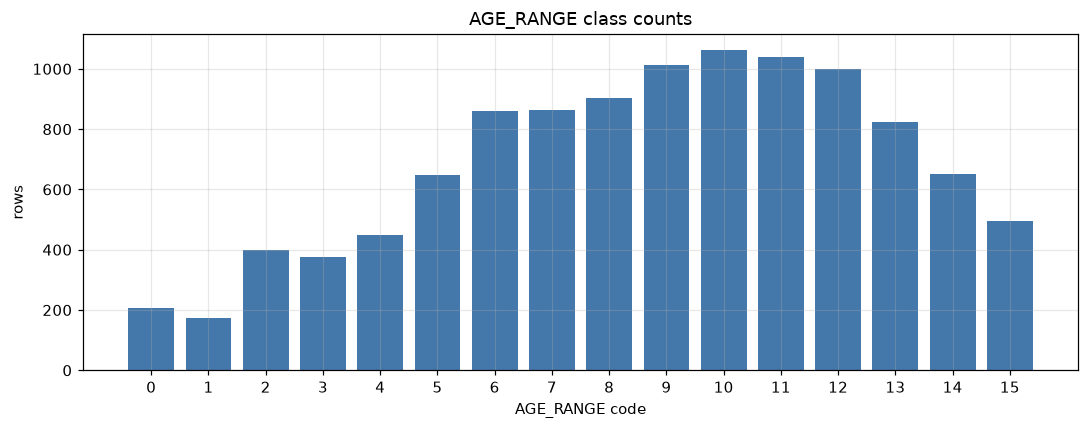

In [4]:
target_counts = train[TARGET].value_counts().sort_index()
target_table = pd.DataFrame(
    {
        "count": target_counts,
        "percent": (100 * target_counts / len(train)).round(2),
        "relative_to_smallest": (target_counts / target_counts.min()).round(2),
    }
)
display(target_table)

print(f"classes: {len(target_counts)}")
print(f"smallest class: {target_counts.idxmin()} with {target_counts.min():,} rows")
print(f"largest class:  {target_counts.idxmax()} with {target_counts.max():,} rows")
print(f"imbalance ratio: {target_counts.max() / target_counts.min():.2f}:1")
print(f"majority-class accuracy baseline: {100 * target_counts.max() / len(train):.2f}%")
print(f"random macro-F1 reference: {1 / len(target_counts):.4f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(target_counts.index.astype(str), target_counts.values, color="#4477aa")
ax.set_title("AGE_RANGE class counts")
ax.set_xlabel("AGE_RANGE code")
ax.set_ylabel("rows")
plt.tight_layout()
plt.show()

## 3. Real missing values versus survey codes

`NaN` means the cell is absent. `"Sem resposta"` and `"Não aplicável"` are answers:
non-response and routing (a question that does not apply to that person). Treating them
as `NaN` would erase information, especially for skip patterns that are themselves
age-related.

In [5]:
missing = train.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print(f"columns containing at least one NaN: {len(missing)}")
display(pd.DataFrame({"missing": missing, "percent": (100 * missing / len(train)).round(2)}))

columns containing at least one NaN: 1


,missing,percent
IN16,5602,51.1000


columns containing each token:


,Sem resposta,Não aplicável,any_sentinel,any_sentinel_pct
columns,210,109,215,215


top columns by sentinel volume:


,Sem resposta,Não aplicável,any_sentinel,any_sentinel_pct
IN13,0,10955,10955,99.9400
IN62,0,10852,10852,99.0000
IN12,4,10674,10678,97.4100
AC_IN2,0,10650,10650,97.1500
IN11,9,10565,10574,96.4600
AC_IN1,0,10549,10549,96.2300
AC2,0,10437,10437,95.2100
PE5,40,10343,10383,94.7200
IN49,3,10288,10291,93.8800
IN4,9,10207,10216,93.1900


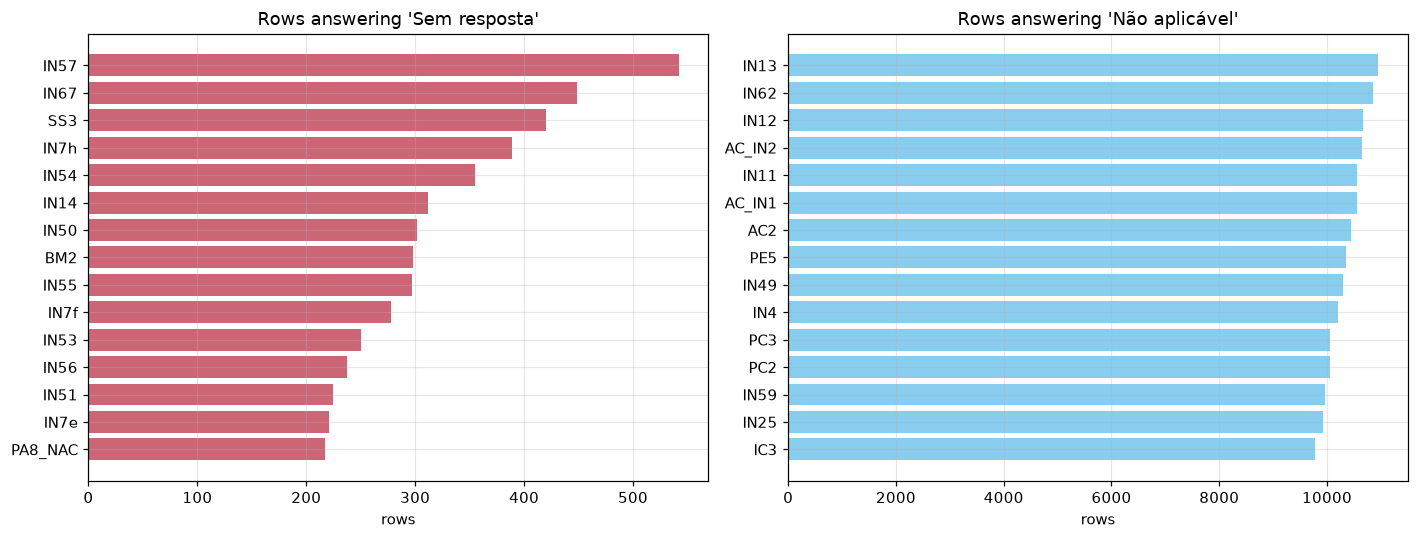

In [6]:
sentinel_counts = pd.DataFrame(
    {token: (train == token).sum() for token in SENTINELS}
)
sentinel_counts["any_sentinel"] = sentinel_counts.sum(axis=1)
sentinel_counts["any_sentinel_pct"] = (
    100 * sentinel_counts["any_sentinel"] / len(train)
).round(2)

print("columns containing each token:")
display(sentinel_counts.gt(0).sum().rename("columns").to_frame().T)
print("top columns by sentinel volume:")
display(sentinel_counts.sort_values("any_sentinel", ascending=False).head(20))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {"Sem resposta": "#cc6677", "Não aplicável": "#88ccee"}
for axis, token in zip(axes, SENTINELS):
    top = sentinel_counts[token].sort_values(ascending=False).head(15).iloc[::-1]
    axis.barh(top.index, top.values, color=colors[token])
    axis.set_title(f"Rows answering {token!r}")
    axis.set_xlabel("rows")
plt.tight_layout()
plt.show()

## 4. Cardinality and identifier audit

Cardinality drives encoding choices. A categorical with a handful of levels can be
one-hot encoded; a column with one hundred levels needs a different plan. Columns whose
cardinality equals the row count are identifiers, not features.

In [7]:
cardinality = column_profile.copy()
cardinality.insert(0, "kind", [column_kind(train[column]) for column in train.columns])
cardinality["n_missing"] = train.isna().sum()

print("level-count summary:")
display(cardinality["n_levels"].describe().to_frame().T)
print("highest-cardinality columns:")
display(cardinality.sort_values("n_levels", ascending=False).head(20))
print("columns with two levels or fewer (excluding the target):")
display(
    cardinality[
        (cardinality["n_levels"] <= 2) & (cardinality.index != TARGET)
    ].sort_values("n_levels")
)

level-count summary:


,count,mean,std,min,25%,50%,75%,max
n_levels,237.0000,103.5696,"1,004.0919",1.0000,4.0000,5.0000,7.0000,"10,962.0000"


highest-cardinality columns:


,kind,n_levels,top_value,top_share,n_missing
PID,numeric,10962,"1,242.0000",0.0001,0
HHID,numeric,10962,"124,201.0000",0.0001,0
PE9,string,165,0200,0.1742,0
IN57,string,144,Não aplicável,0.5660,0
IN55,string,135,Não aplicável,0.7970,0
IN56,string,120,Não aplicável,0.8918,0
PE7,string,102,Não aplicável,0.7261,0
BM2,string,102,70.0,0.0686,0
IN45,string,73,Não aplicável,0.7844,0
IN4,string,70,Não aplicável,0.9311,0


columns with two levels or fewer (excluding the target):


,kind,n_levels,top_value,top_share,n_missing
PROXY,numeric,1,1.0000,1.0000,0
COUNTRY,string,1,PT,1.0000,0
REFYEAR,numeric,2,2019,0.9802,0
SEX,string,2,Mulher,0.5705,0


In [8]:
numeric_columns = [
    column for column in train.columns if pd.api.types.is_numeric_dtype(train[column])
]
display(train[numeric_columns].describe().T)
print("REFYEAR values:", train["REFYEAR"].value_counts().to_dict())
print("REFMONTH range:", int(train["REFMONTH"].min()), "to", int(train["REFMONTH"].max()))

,count,mean,std,min,25%,50%,75%,max
PID,"10,962.0000","7,265.8010","4,228.3638",2.0000,"3,588.2500","7,250.0000","10,906.7500","14,617.0000"
HHID,"10,962.0000","726,581.6164","422,836.4032",201.0000,"358,826.0000","725,001.5000","1,090,676.7500","1,461,702.0000"
PROXY,"10,962.0000",1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
REFYEAR,"10,962.0000","2,019.0198",0.1393,"2,019.0000","2,019.0000","2,019.0000","2,019.0000","2,020.0000"
REFMONTH,"10,962.0000",10.3652,1.5940,1.0000,10.0000,10.0000,11.0000,12.0000
AGE_RANGE,"10,962.0000",8.7562,3.7653,0.0000,6.0000,9.0000,12.0000,15.0000
HH_ACT,"10,962.0000",0.9350,0.9609,0.0000,0.0000,1.0000,2.0000,6.0000
HH_INACT,"10,962.0000",0.4722,0.7312,0.0000,0.0000,0.0000,1.0000,5.0000


REFYEAR values: {2019: 10745, 2020: 217}
REFMONTH range: 1 to 12


## 5. Raw value formats

Some columns look numeric but are strings. Casting them blindly can destroy leading
zeros and fixed-width codes, and some columns mix numbers with range labels. This section
lists those columns; it does not change them.

In [9]:
def non_sentinel_values(series):
    # Return non-null values with survey response codes removed, as strings.
    values = series.dropna().astype(str)
    return values[~values.isin(SENTINELS)]


numeric_like_rows = []
for column in train.columns:
    if not pd.api.types.is_string_dtype(train[column]):
        continue
    values = non_sentinel_values(train[column])
    if values.empty:
        continue
    if values.str.fullmatch(r"-?\d+(?:\.\d+)?").all():
        numeric_like_rows.append(
            {
                "column": column,
                "n_values": len(values),
                "n_unique": values.nunique(),
                "leading_zero_values": int(values.str.fullmatch(r"0\d+").sum()),
                "example_values": ", ".join(values.drop_duplicates().head(3)),
            }
        )

numeric_like = pd.DataFrame(numeric_like_rows).sort_values(
    "n_unique", ascending=False
)
print(f"string columns whose non-sentinel values are all numeric: {len(numeric_like)}")
display(numeric_like)

string columns whose non-sentinel values are all numeric: 23


,column,n_values,n_unique,leading_zero_values,example_values
12,PE9,10826,164,9520,"0200, 0300, 0400"
21,IN57,4216,142,0,"40.0, 20.0, 50.0"
19,IN55,1928,133,0,"248.0, 50.0, 7.0"
20,IN56,949,118,0,"5.0, 12.0, 100.0"
6,BM2,10664,101,0,"69.0, 54.0, 72.0"
10,PE7,2873,100,2729,"0130, 0100, 1230"
17,IN45,2232,71,0,"41.0, 30.0, 50.0"
2,IN4,746,68,0,"37.0, 42.0, 44.0"
5,BM1,10747,65,0,"179.0, 175.0, 159.0"
1,IN3,1273,63,0,"27.0, 38.0, 16.0"


In [10]:
mixed_format_rows = []
for column in train.columns:
    if not pd.api.types.is_string_dtype(train[column]):
        continue
    values = non_sentinel_values(train[column])
    if values.empty:
        continue
    numeric_share = values.str.fullmatch(r"-?\d+(?:\.\d+)?").mean()
    if 0 < numeric_share < 1:
        mixed_format_rows.append(
            {
                "column": column,
                "numeric_share": round(float(numeric_share), 4),
                "examples": " | ".join(values.drop_duplicates().head(4)),
            }
        )

print("string columns mixing numeric and non-numeric values:")
display(pd.DataFrame(mixed_format_rows))

string columns mixing numeric and non-numeric values:


,column,numeric_share,examples
0,HHNBPERS_COD,0.9964,1.0 | 5.0 | 2.0 | 4.0
1,HHNBPERS_0_13_COD,0.9920,0.0 | 2.0 | 1.0 | >=3
2,HO12_COD,0.9915,0.0 | 3.0 | 21.0 | 12.0
3,HO34_COD,0.9990,0.0 | 2.0 | 1.0 | 20.0
4,PA1,0.2243,Há mais de 1 ano | 201911 | Nunca | 201910
5,IN24,0.9723,2007.0 | 2008.0 | 1999.0 | 1997.0
6,IN25,0.9850,1.0 | 24.0 | 12.0 | 16.0
7,IN26,0.9963,5.0 | 16.0 | 8.0 | 9.0


## 6. Association with `AGE_RANGE`

Cramér's V measures how strongly each low-cardinality categorical is associated with the
target, with a chi-square test for reference. It is descriptive: it ignores interactions
and it is not the same as model importance. High-cardinality columns are excluded rather
than silently binned, because binning would be a transformation.

features evaluated: 221


,column,n_levels,cramers_v,p_value
80,PC1E,6,0.4778,0.0000
78,PC1C,6,0.4653,0.0000
77,PC1B,6,0.4643,0.0000
79,PC1D,6,0.4607,0.0000
83,IN15,6,0.4553,0.0000
76,PC1A,6,0.4524,0.0000
86,HA1C,7,0.4442,0.0000
89,HA1F,7,0.4439,0.0000
88,HA1E,7,0.4372,0.0000
84,HA1A,7,0.4321,0.0000


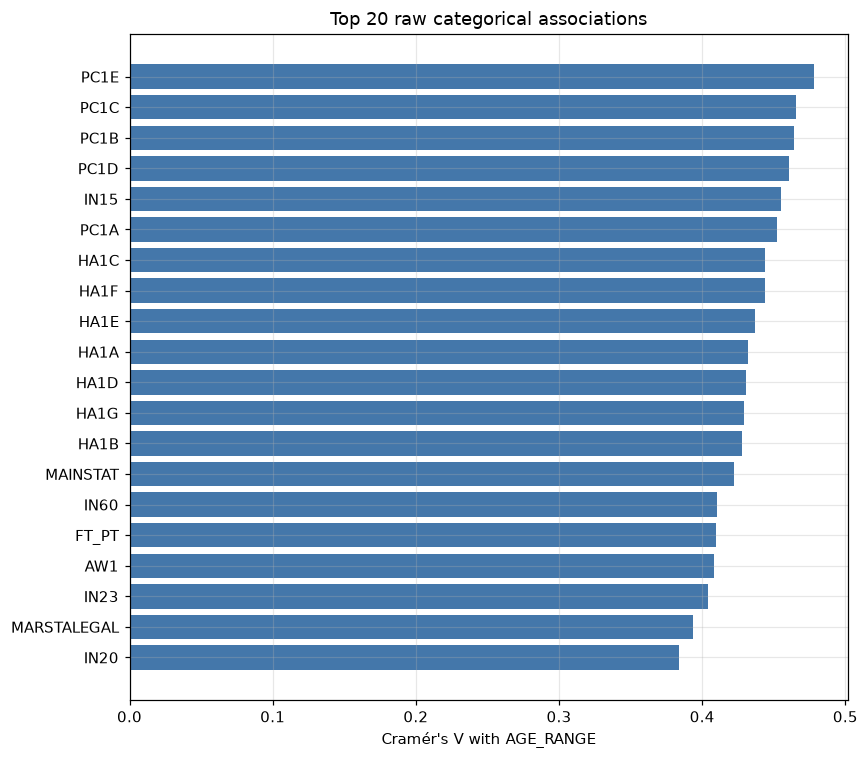

In [11]:
def cramers_v(feature, target):
    # Return Cramér's V and the chi-square p-value for two categorical series.
    table = pd.crosstab(feature, target, dropna=False)
    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan, np.nan
    chi2, p_value, _, _ = chi2_contingency(table, correction=False)
    n_observations = table.values.sum()
    v = np.sqrt((chi2 / n_observations) / (min(table.shape) - 1))
    return float(v), float(p_value)


association_rows = []
for column in train.columns:
    if column in (TARGET, "PID", "HHID"):
        continue
    n_levels_column = train[column].nunique(dropna=False)
    if n_levels_column < 2 or n_levels_column > 60:
        continue
    v, p_value = cramers_v(train[column], train[TARGET])
    association_rows.append(
        {
            "column": column,
            "n_levels": n_levels_column,
            "cramers_v": v,
            "p_value": p_value,
        }
    )

association = pd.DataFrame(association_rows).sort_values(
    "cramers_v", ascending=False
)
print(f"features evaluated: {len(association)}")
display(association.head(30))

top_association = association.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top_association["column"], top_association["cramers_v"], color="#4477aa")
ax.set_xlabel("Cramér's V with AGE_RANGE")
ax.set_title("Top 20 raw categorical associations")
plt.tight_layout()
plt.show()

## 7. Target profile of key socioeconomic and health fields

These row-normalised tables show the age-class mix inside each category. They are useful
for spotting routing effects (for example, questions only asked above a certain age) and
for deciding which variables deserve ordinal treatment.

In [12]:
CROSSTAB_COLUMNS = [
    "SEX",
    "HS1",
    "HS3",
    "MAINSTAT",
    "HATLEVEL",
    "REGION",
    "HHINCOME",
]

for column in CROSSTAB_COLUMNS:
    table = pd.crosstab(train[column], train[TARGET], normalize="index") * 100
    table = table.round(1)
    table["n"] = train[column].value_counts()
    print(f"\n{column} (row percentages, target columns 0-15)")
    display(table)


SEX (row percentages, target columns 0-15)


AGE_RANGE,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,n
SEX,,,,,,,,,,,,,,,,,
Homem,2.0000,1.9000,4.1000,3.7000,3.9000,6.0000,8.2000,8.3000,8.2000,10.2000,9.3000,10.1000,8.8000,6.4000,5.1000,3.8000,4708
Mulher,1.8000,1.3000,3.3000,3.3000,4.3000,5.9000,7.6000,7.5000,8.3000,8.6000,9.9000,9.0000,9.4000,8.3000,6.5000,5.0000,6254



HS1 (row percentages, target columns 0-15)


AGE_RANGE,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,n
HS1,,,,,,,,,,,,,,,,,
Bom,2.9000,2.1000,5.5000,5.3000,6.9000,9.9000,12.2000,9.8000,9.5000,9.8000,8.2000,7.4000,4.4000,2.5000,2.2000,1.4000,3712
Mau,0.1000,0.0000,0.3000,0.3000,0.6000,0.6000,1.8000,3.3000,6.0000,7.0000,10.5000,11.3000,14.3000,17.2000,15.0000,11.7000,1293
Muito bom,7.2000,6.5000,11.2000,10.6000,9.0000,10.5000,11.7000,9.8000,6.6000,5.7000,3.7000,2.7000,2.4000,1.0000,0.6000,1.0000,1145
Muito mau,0.0000,0.3000,0.3000,0.5000,1.0000,0.8000,1.3000,3.8000,3.5000,6.3000,10.9000,8.6000,14.1000,16.7000,16.4000,15.7000,396
Razoável,0.4000,0.4000,1.4000,1.2000,1.8000,3.3000,5.4000,7.4000,8.7000,10.7000,12.2000,12.6000,12.9000,9.8000,6.9000,5.0000,4396
Sem resposta,0.0000,5.0000,0.0000,0.0000,0.0000,15.0000,20.0000,20.0000,0.0000,0.0000,0.0000,5.0000,15.0000,0.0000,5.0000,15.0000,20



HS3 (row percentages, target columns 0-15)


...

AGE_RANGE,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,n
HATLEVEL,,,,,,,,,,,,,,,,,
Bacharelato ou licenciatura 1º ciclo,0.0000,0.4000,13.4000,14.5000,10.3000,7.9000,8.1000,7.0000,6.0000,5.0000,7.4000,6.2000,5.0000,4.1000,2.1000,2.5000,516
Básico 1º e 2º ciclo,0.9000,0.1000,0.4000,0.6000,1.2000,1.9000,3.8000,6.2000,9.0000,10.7000,13.6000,14.2000,14.8000,10.9000,6.9000,4.8000,4310
Básico 3º ciclo,8.9000,3.3000,3.6000,3.8000,5.6000,8.3000,9.6000,9.1000,9.1000,11.4000,9.1000,7.9000,4.6000,3.1000,1.7000,1.1000,1830
C.T.Superior Profissional,0.0000,5.4000,7.1000,14.3000,10.7000,12.5000,5.4000,3.6000,5.4000,10.7000,5.4000,7.1000,1.8000,7.1000,3.6000,0.0000,56
Doutoramento,0.0000,0.0000,1.8000,1.8000,3.5000,8.8000,15.8000,8.8000,14.0000,17.5000,5.3000,12.3000,1.8000,7.0000,1.8000,0.0000,57
Licenciatura pré-bolonha ou mestrado 2º ciclo,0.0000,0.0000,1.3000,3.7000,6.6000,12.2000,19.1000,14.4000,11.1000,8.6000,7.2000,7.1000,4.1000,2.4000,1.0000,1.0000,1148
Nenhum nível completado,0.2000,0.0000,0.0000,0.2000,0.4000,0.5000,0.4000,1.5000,2.7000,3.9000,5.7000,6.4000,12.9000,19.5000,24.9000,20.8000,1129
Pós secundário,0.8000,0.0000,7.1000,8.7000,11.8000,11.8000,13.4000,11.0000,9.4000,6.3000,6.3000,4.7000,5.5000,2.4000,0.0000,0.8000,127
Secundário,0.1000,5.7000,12.2000,7.9000,7.8000,11.2000,12.7000,10.7000,7.7000,8.6000,6.2000,4.4000,2.6000,1.1000,0.7000,0.3000,1789



REGION (row percentages, target columns 0-15)


AGE_RANGE,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,n
REGION,,,,,,,,,,,,,,,,,
Alentejo,1.2000,1.0000,3.0000,2.5000,3.4000,4.3000,6.9000,7.3000,6.8000,10.4000,10.4000,9.3000,10.4000,8.1000,8.8000,6.2000,1848
Algarve,1.4000,1.4000,3.7000,3.5000,5.1000,7.5000,8.7000,6.4000,7.9000,10.1000,9.2000,8.6000,8.8000,7.3000,5.4000,5.1000,1282
Centro (PT),1.6000,1.7000,3.4000,3.0000,2.9000,4.7000,6.0000,7.5000,8.1000,7.9000,10.0000,10.0000,10.4000,9.2000,7.6000,5.8000,2315
Lisboa,1.9000,1.9000,4.4000,5.2000,4.9000,7.3000,9.0000,8.5000,8.7000,8.0000,8.5000,9.8000,7.8000,6.4000,5.3000,2.4000,1022
Norte,2.2000,1.7000,3.3000,3.9000,4.1000,5.3000,8.1000,7.4000,7.5000,8.5000,9.8000,11.6000,10.6000,7.4000,5.2000,3.4000,1625
Região Autónoma da Madeira,2.5000,1.8000,3.6000,2.5000,3.6000,6.3000,7.8000,9.7000,10.0000,11.1000,10.3000,8.2000,7.5000,7.1000,4.3000,3.6000,1427
Região Autónoma dos Açores,2.8000,1.6000,4.6000,4.4000,5.9000,7.7000,10.1000,8.7000,9.4000,8.9000,8.8000,8.5000,6.5000,5.5000,3.0000,3.5000,1443



HHINCOME (row percentages, target columns 0-15)


AGE_RANGE,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,n
HHINCOME,,,,,,,,,,,,,,,,,
1º quintil,6.2000,4.5000,7.5000,4.6000,4.8000,6.3000,8.2000,9.4000,8.8000,9.8000,10.8000,6.8000,3.4000,3.9000,2.5000,2.6000,2132
2º quintil,0.9000,0.9000,2.3000,2.8000,2.8000,4.1000,5.1000,4.2000,5.0000,5.2000,5.4000,10.7000,15.1000,13.1000,12.4000,9.9000,2712
3º quintil,0.9000,1.0000,2.9000,2.9000,3.0000,4.8000,6.8000,6.6000,8.7000,9.0000,12.2000,9.8000,11.5000,9.1000,6.9000,3.9000,2207
4º quintil,1.2000,0.7000,3.6000,4.0000,5.3000,9.5000,10.5000,9.4000,10.3000,12.3000,10.5000,8.2000,5.3000,4.3000,2.8000,2.3000,1933
5º quintil,0.5000,0.9000,2.3000,3.1000,5.1000,5.7000,9.8000,11.1000,9.6000,11.6000,10.8000,11.6000,8.1000,5.0000,2.8000,2.1000,1978


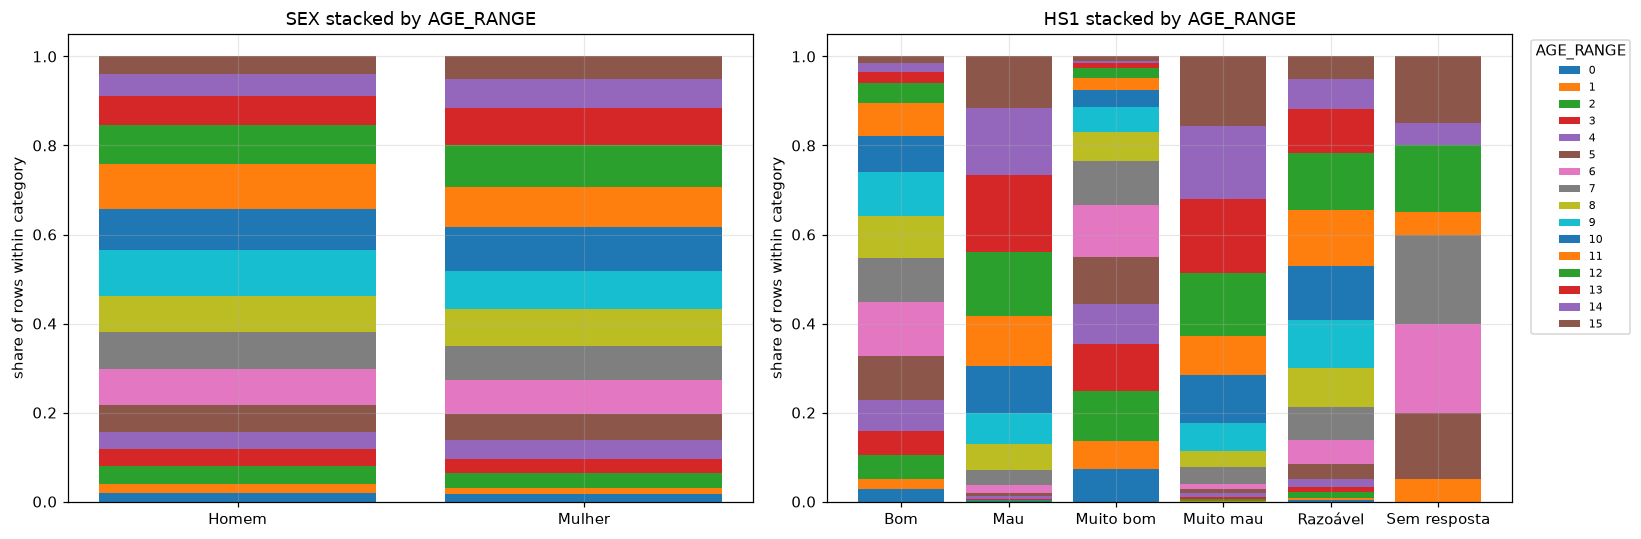

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for axis, column in zip(axes, ["SEX", "HS1"]):
    shares = pd.crosstab(train[column], train[TARGET], normalize="index")
    bottom = np.zeros(len(shares))
    for target_code in shares.columns:
        axis.bar(
            shares.index.astype(str),
            shares[target_code].values,
            bottom=bottom,
            label=str(target_code),
        )
        bottom += shares[target_code].values
    axis.set_title(f"{column} stacked by AGE_RANGE")
    axis.set_ylabel("share of rows within category")
axes[1].legend(
    title="AGE_RANGE", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7, ncol=1
)
plt.tight_layout()
plt.show()

## 8. Train/test comparability

The test set is scored on Macro F1, so unseen categories and distribution shifts matter.
Total variation distance (TVD) is a simple summary: 0 means identical distributions, 1
means disjoint support. Levels present only in test are listed separately, because a
model that has never seen them cannot assign them a learned coefficient.

largest train/test distribution distances:


,column,levels,tvd
196,IN47,56,0.0354
135,PA8_NAC,8,0.0268
5,REGION,7,0.0261
200,AL1,10,0.0258
206,IN50,8,0.0255
178,DH4,16,0.0255
209,IN53,8,0.0254
6,NUTS2_AG,7,0.0244
28,HHINCOME,5,0.0242
108,IN16,11,0.0222


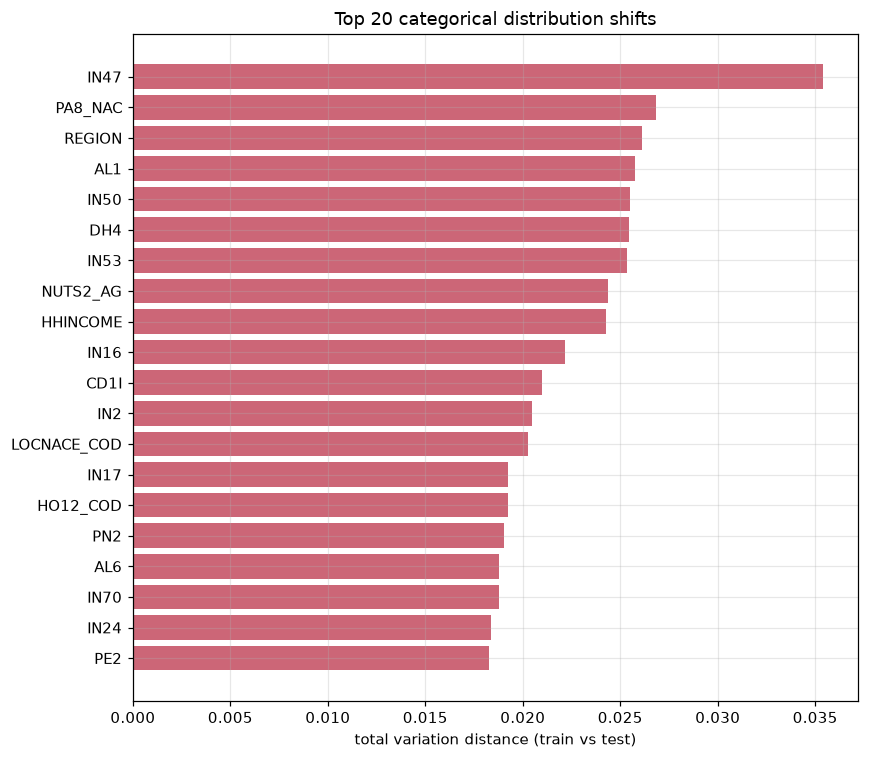

In [14]:
drift_rows = []
for column in test.columns:
    if train[column].nunique(dropna=False) > 60:
        continue
    train_share = train[column].value_counts(normalize=True, dropna=False)
    test_share = test[column].value_counts(normalize=True, dropna=False)
    levels = train_share.index.union(test_share.index)
    tvd = 0.5 * np.abs(
        train_share.reindex(levels, fill_value=0)
        - test_share.reindex(levels, fill_value=0)
    ).sum()
    drift_rows.append({"column": column, "levels": len(levels), "tvd": float(tvd)})

drift = pd.DataFrame(drift_rows).sort_values("tvd", ascending=False)
print("largest train/test distribution distances:")
display(drift.head(20))

top_drift = drift.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top_drift["column"], top_drift["tvd"], color="#cc6677")
ax.set_xlabel("total variation distance (train vs test)")
ax.set_title("Top 20 categorical distribution shifts")
plt.tight_layout()
plt.show()

In [15]:
unseen_rows = []
for column in test.columns:
    if column in ("PID", "HHID"):
        continue
    train_levels = set(train[column].dropna().unique())
    test_levels = set(test[column].dropna().unique())
    new_levels = test_levels - train_levels
    if new_levels:
        unseen_rows.append(
            {
                "column": column,
                "n_unseen": len(new_levels),
                "examples": " | ".join(sorted(map(str, new_levels))[:5]),
            }
        )

unseen = pd.DataFrame(unseen_rows).sort_values("n_unseen", ascending=False)
print("identifiers PID/HHID are excluded: every identifier is new in test")
print(f"feature columns with at least one test-only level: {len(unseen)}")
display(unseen)

identifiers PID/HHID are excluded: every identifier is new in test
feature columns with at least one test-only level: 20


,column,n_unseen,examples
12,PE9,15,0034 | 0038 | 0112 | 0211 | 0225
18,IN57,13,127.0 | 132.0 | 142.0 | 162.0 | 187.0
11,PE7,13,0055 | 0259 | 0302 | 0310 | 0359
16,IN55,13,164.0 | 195.0 | 209.0 | 42.0 | 420.0
17,IN56,10,134.0 | 156.0 | 185.0 | 29.0 | 38.0
19,IN59,9,268.0 | 280.0 | 310.0 | 42.0 | 452.0
1,IN3,6,59.0 | 60.0 | 68.0 | 70.0 | 73.0
15,IN47,4,55.0 | 58.0 | 67.0 | 70.0
0,IN2,3,51.0 | 52.0 | 60.0
2,IN4,2,61.0 | 89.0


## 9. Decision summary

The table below turns the statistics above into explicit choices for the modelling
pipeline. It is a reading aid, not an automated preprocessing step.

| Observation | Consequence |
|---|---|
| `PROXY` and `COUNTRY` are constant | Drop them; they carry no information. |
| `AC1A` is 99.0% one value; `IN13` is 99.9% one value | Keep only if domain knowledge justifies it; otherwise drop or treat as a rare category. |
| Only `IN16` contains real `NaN` (51.1%) | Do not impute blindly; preserve absence and decide whether the field is usable. |
| `"Sem resposta"` / `"Não aplicável"` are widespread | Keep them as explicit categories; they encode non-response and questionnaire routing. |
| `PID`/`HHID` are unique per row and do not overlap with test | Treat as identifiers, never as features; `HHID` does not group households in this export. |
| `PE9`, `IN57`, `IN55`, `IN56`, `BM2`, `PE7` are high-cardinality | Avoid one-hot; parse only after checking the raw code format. |
| Some numeric-looking strings have leading zeros (`PE7`, `PE9`) | Do not cast blindly; preserve the fixed-width code or parse with a documented rule. |
| `HHNBPERS_COD`, `HHNBPERS_0_13_COD` mix numbers and `">=7"`/`">=3"` | Parse as ordinal with an explicit bucket rule, not as raw numeric. |
| Cramér's V is highest for `PC1E`, `PC1C`, `PC1B`, `PC1D`, `IN15`, `PC1A`, `HA1*` | Prioritise autonomy/daily-task variables for interpretation and feature engineering. |
| `MAINSTAT`, `FT_PT`, `MARSTALEGAL`, `JOBSTAT_COD` are also strongly associated | Expect socioeconomic status to carry substantial signal. |
| Test contains unseen levels in several columns | Encode with an explicit unknown bucket or a model that tolerates unseen categories. |
| Train/test TVD is small (maximum about 0.035) | No evidence of a major distribution shift; ordinary stratified validation is reasonable. |
| Classes range from 172 to 1,062 rows | Use stratification, class weights or macro-F1-aware validation; accuracy is misleading. |